<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Spirulina-based-Microcapsules-Control-Release/blob/main/Note_1_Feed_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# PART 1
# Load Library
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

In [ ]:
# ==========================================================
# PART 2
# Load Dataset
# ==========================================================

df = pd.read_excel("Datasets Final.xlsx")

print("="*60)
print("Dataset Shape")
print(df.shape)

print("="*60)
print(df.head())

Dataset Shape
(150, 607)
  Sample_ID Spirulina_Size  Load    Medium  Time_h   Release    A_200  \
0      S001           Nano   0.5  Aquadest       0  0.000000  0.00358   
1      S002           Nano   0.5  Aquadest       1  0.000089  0.00292   
2      S003           Nano   0.5  Aquadest       2  0.000155  0.00000   
3      S004           Nano   0.5  Aquadest       3  0.000299  0.00233   
4      S005           Nano   0.5  Aquadest       4  0.000406  0.00000   

      A_201    A_202    A_203  ...     A_791     A_792     A_793     A_794  \
0  0.003760  0.00543  0.00685  ...  0.000068  0.000056  0.000045  0.000032   
1  0.004560  0.00417  0.00320  ...  0.000401  0.000399  0.000394  0.000383   
2  0.005190  0.00995  0.01429  ...  0.000853  0.000811  0.000768  0.000721   
3  0.000172  0.00000  0.00132  ...  0.000683  0.000679  0.000674  0.000669   
4  0.003990  0.00498  0.00401  ...  0.000227  0.000231  0.000237  0.000245   

      A_795     A_796     A_797     A_798     A_799     A_800  
0  

In [ ]:
# ==========================================================
# PART 3
# Data Information
# ==========================================================

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Columns: 607 entries, Sample_ID to A_800
dtypes: float64(603), int64(1), object(3)
memory usage: 711.5+ KB
None


In [ ]:
# ==========================================================
# PART 4
# Missing Value
# ==========================================================

missing = df.isnull().sum()

missing = missing[missing>0]

print(missing)

print("\nTotal Missing :",df.isnull().sum().sum())

Series([], dtype: int64)

Total Missing : 0


In [ ]:
# ==========================================================
# PART 5
# Separate Metadata & Spectrum
# ==========================================================

metadata_cols = [
    "Sample_ID",
    "Spirulina_Size",
    "Load",
    "Medium",
    "Time_h",
    "Repetition",
]

target_cols= [
    "Release"
  ]

spectral_cols = [c for c in df.columns if c.startswith("A_")]

print("Metadata :",len(metadata_cols))
print("Spectral :",len(spectral_cols))

Metadata : 6
Spectral : 601


In [ ]:
# ==========================================================
# PART 6
# Encode Categorical Variable
# ==========================================================

df_ml = df.copy()

le_size = LabelEncoder()
le_medium = LabelEncoder()

df_ml["Spirulina_Size"] = le_size.fit_transform(
    df_ml["Spirulina_Size"]
)

df_ml["Medium"] = le_medium.fit_transform(
    df_ml["Medium"]
)

print(le_size.classes_)
print(le_medium.classes_)

['Micro' 'Nano']
['Aquadest' 'SGF' 'SIF']


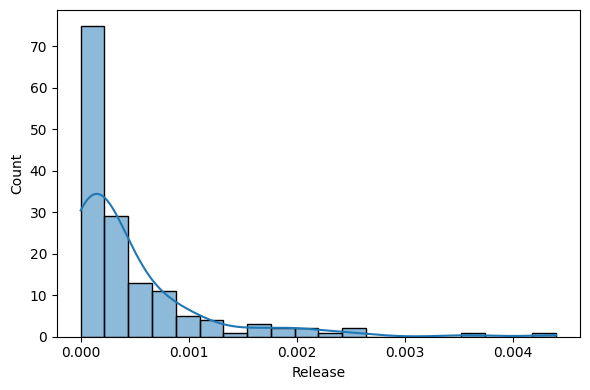

In [ ]:
plt.figure(figsize=(6,4))

sns.histplot(
    df["Release"],
    bins=20,
    kde=True
)

plt.xlabel("Release")

plt.ylabel("Count")

plt.tight_layout()

plt.show()

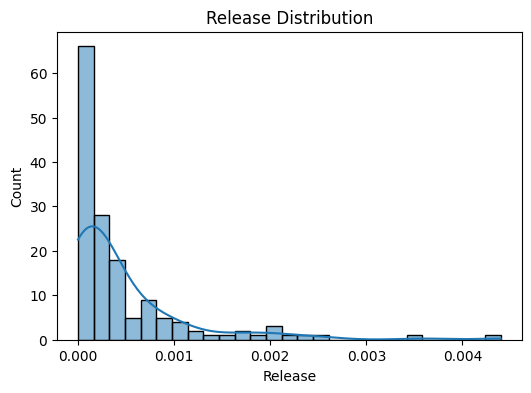

In [ ]:
plt.figure(figsize=(6,4))

sns.histplot(
    df["Release"],
    kde=True
)

plt.title("Release Distribution")

plt.show()

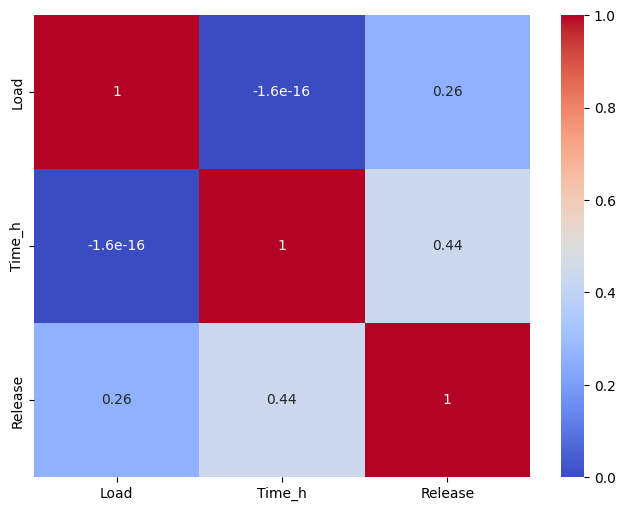

In [ ]:
target_cols = [
    "Release"
]

# Memastikan hanya kolom yang benar-benar ada di df yang akan dipanggil
existing_metadata_cols = [col for col in metadata_cols if col in df.columns]

meta_df = df[
    existing_metadata_cols +
    target_cols
]

plt.figure(figsize=(8,6))

sns.heatmap(
    meta_df.corr(
        numeric_only=True
    ),
    annot=True,
    cmap="coolwarm"
)

plt.show()

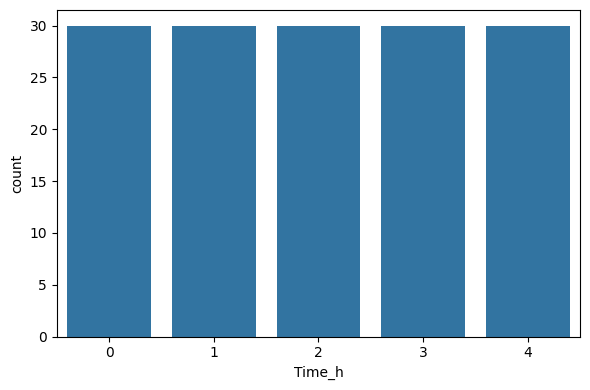

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Time_h"
)

plt.tight_layout()

plt.show()

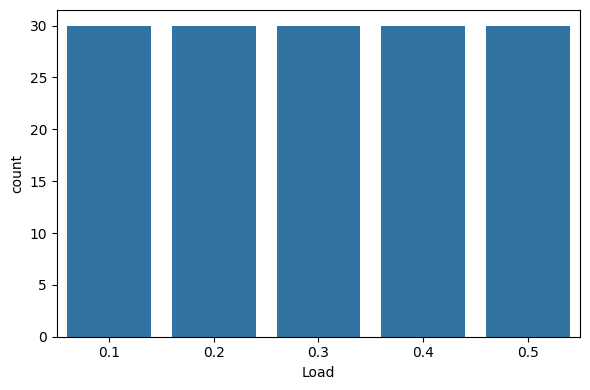

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Load"
)

plt.tight_layout()

plt.show()

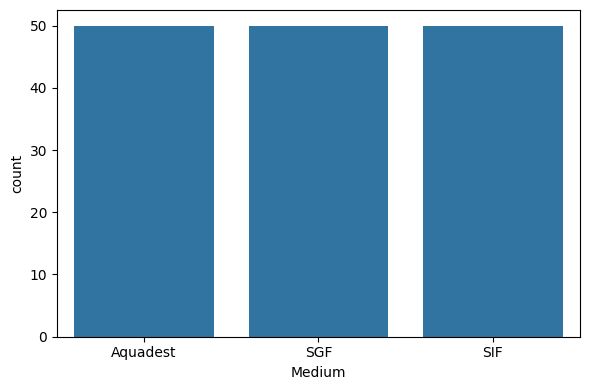

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Medium"
)

plt.tight_layout()

plt.show()

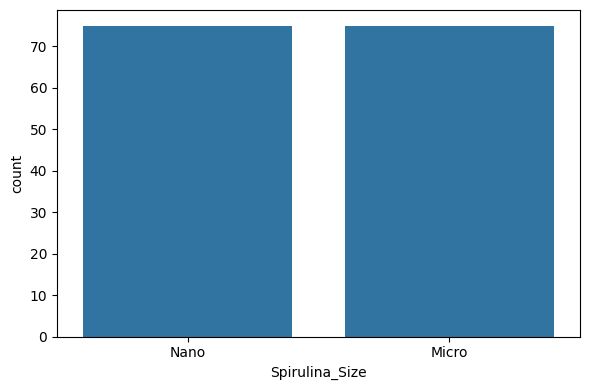

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Spirulina_Size"
)

plt.tight_layout()

plt.show()

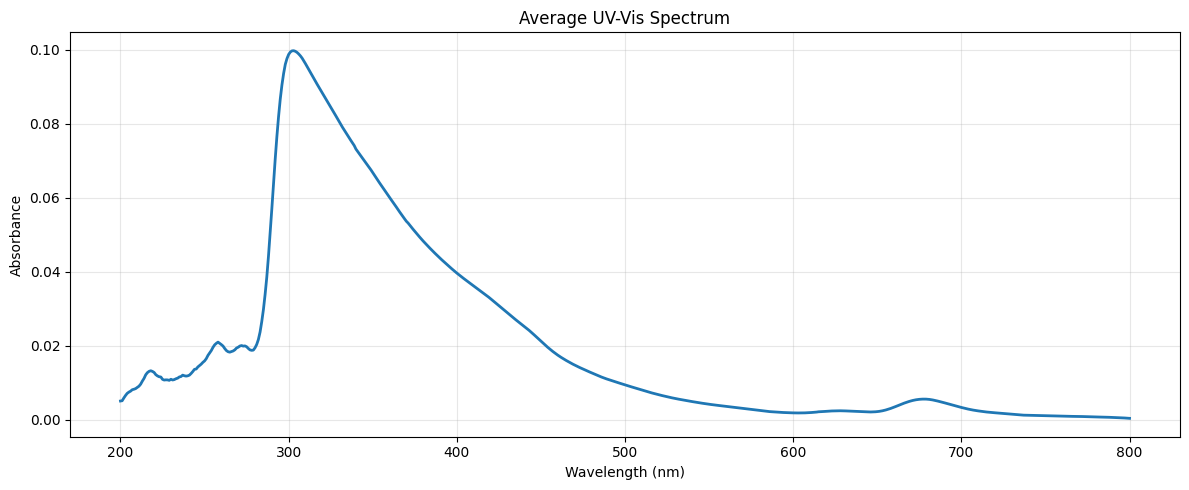

In [ ]:
X_spec = df[spectral_cols].values

wavelength = [
    int(i.split("_")[1])
    for i in spectral_cols
]

plt.figure(figsize=(12,5))

plt.plot(
    wavelength,
    X_spec.mean(axis=0),
    linewidth=2
)

plt.xlabel("Wavelength (nm)")

plt.ylabel("Absorbance")

plt.title("Average UV-Vis Spectrum")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

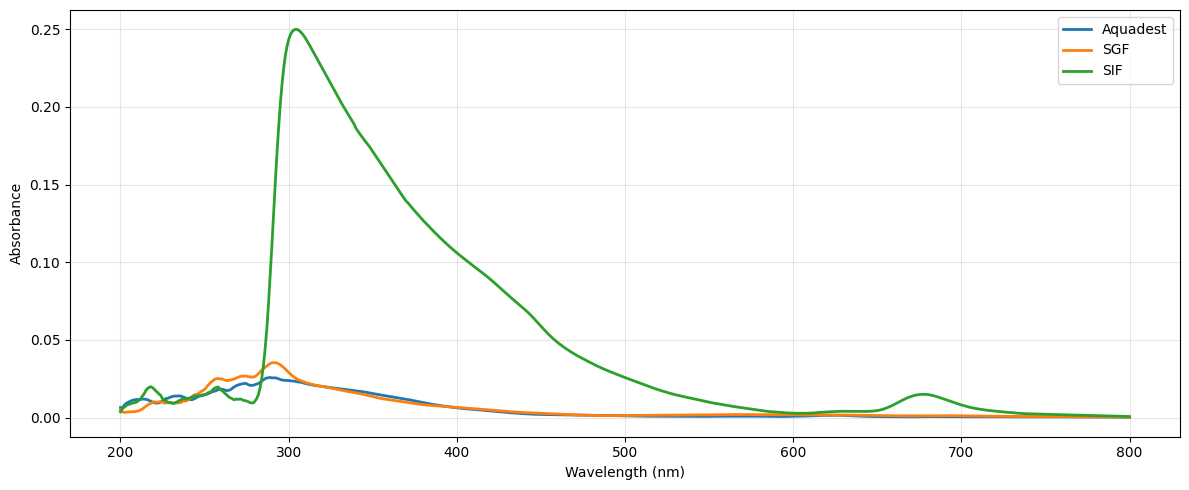

In [ ]:
plt.figure(figsize=(12,5))

for medium in df["Medium"].unique():

    idx = df["Medium"]==medium

    plt.plot(
        wavelength,
        X_spec[idx].mean(axis=0),
        linewidth=2,
        label=medium
    )

plt.legend()

plt.xlabel("Wavelength (nm)")

plt.ylabel("Absorbance")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

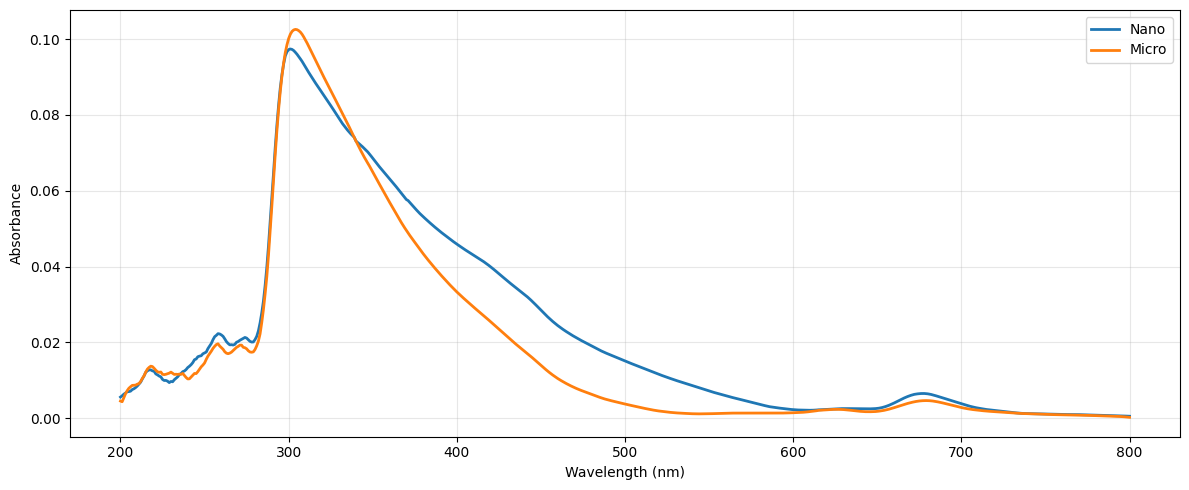

In [ ]:
plt.figure(figsize=(12,5))

for size in df["Spirulina_Size"].unique():

    idx = df["Spirulina_Size"]==size

    plt.plot(
        wavelength,
        X_spec[idx].mean(axis=0),
        linewidth=2,
        label=size
    )

plt.legend()

plt.xlabel("Wavelength (nm)")

plt.ylabel("Absorbance")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

### Spectrum Wavelength Absorbance by Spirulina Size and Medium

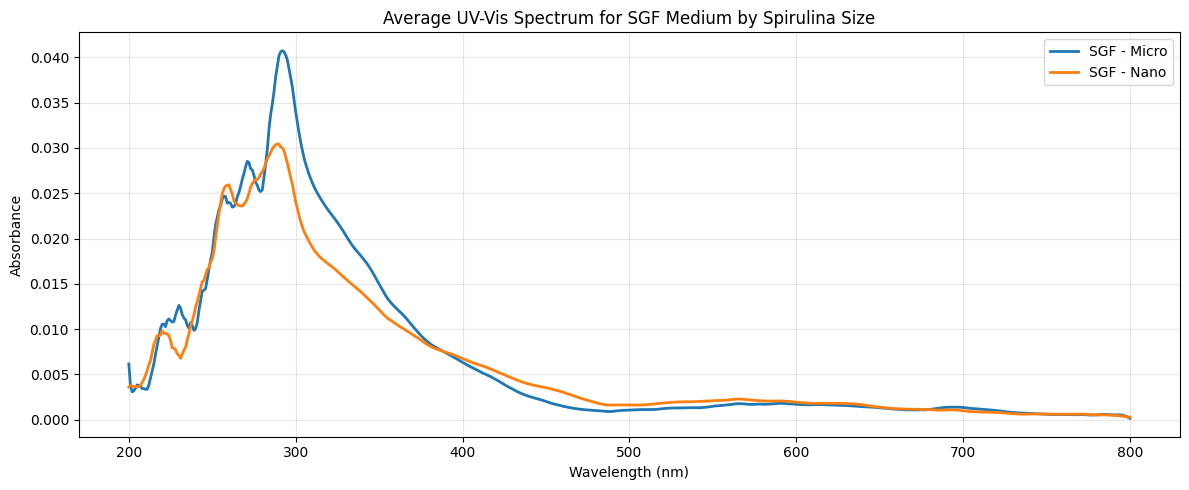

In [ ]:
# Plot for Medium: SGF
plt.figure(figsize=(12,5))

medium_filter_df = df[df["Medium"] == "SGF"]

for size in sorted(medium_filter_df["Spirulina_Size"].unique()):
    idx = (df["Medium"] == "SGF") & (df["Spirulina_Size"] == size)
    plt.plot(
        wavelength,
        X_spec[idx].mean(axis=0),
        linewidth=2,
        label=f"SGF - {size}"
    )

plt.legend()
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.title("Average UV-Vis Spectrum for SGF Medium by Spirulina Size")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

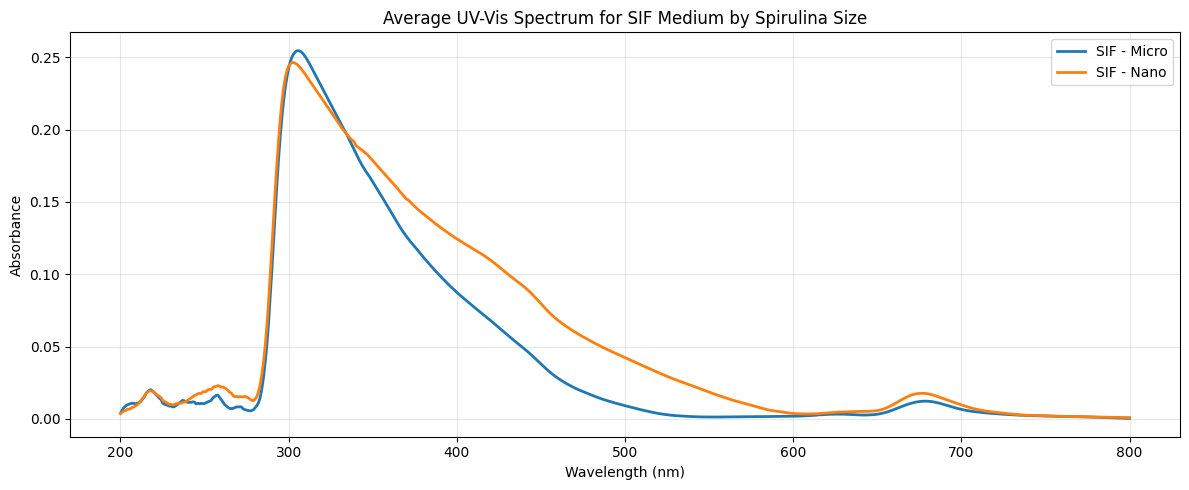

In [ ]:
# Plot for Medium: SIF
plt.figure(figsize=(12,5))

medium_filter_df = df[df["Medium"] == "SIF"]

for size in sorted(medium_filter_df["Spirulina_Size"].unique()):
    idx = (df["Medium"] == "SIF") & (df["Spirulina_Size"] == size)
    plt.plot(
        wavelength,
        X_spec[idx].mean(axis=0),
        linewidth=2,
        label=f"SIF - {size}"
    )

plt.legend()
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.title("Average UV-Vis Spectrum for SIF Medium by Spirulina Size")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

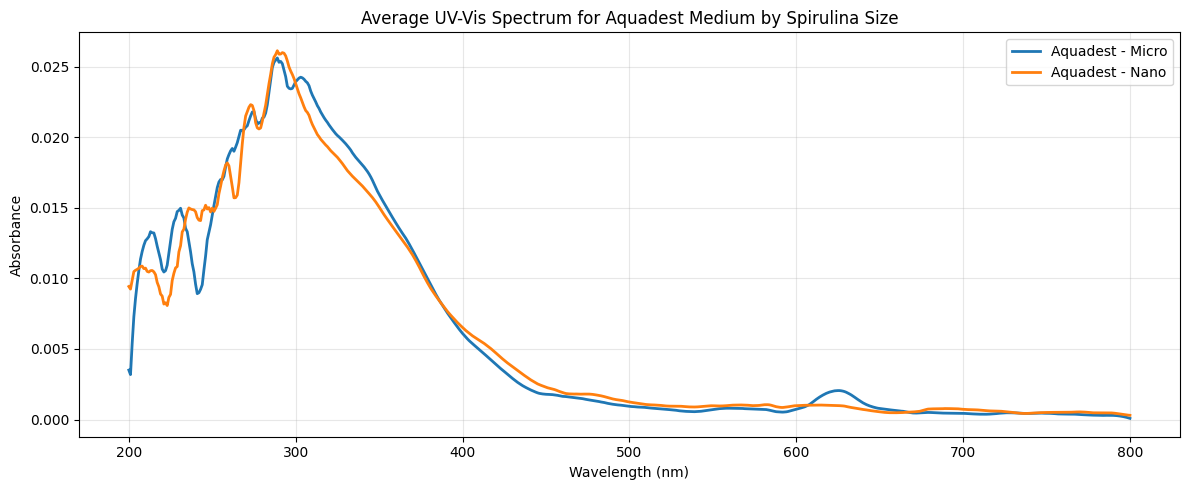

In [ ]:
# Plot for Medium: Aquadest
plt.figure(figsize=(12,5))

medium_filter_df = df[df["Medium"] == "Aquadest"]

for size in sorted(medium_filter_df["Spirulina_Size"].unique()):
    idx = (df["Medium"] == "Aquadest") & (df["Spirulina_Size"] == size)
    plt.plot(
        wavelength,
        X_spec[idx].mean(axis=0),
        linewidth=2,
        label=f"Aquadest - {size}"
    )

plt.legend()
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.title("Average UV-Vis Spectrum for Aquadest Medium by Spirulina Size")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

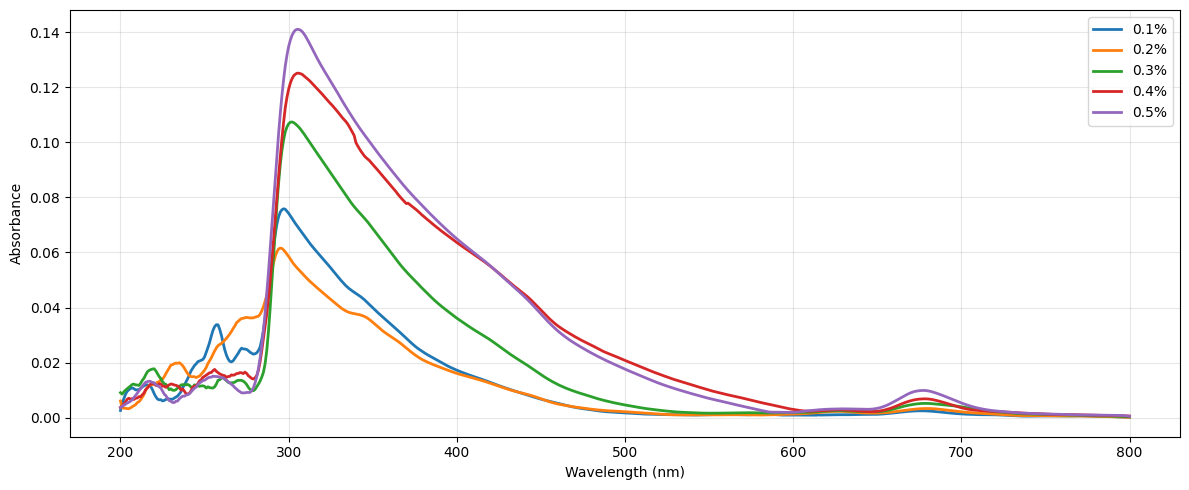

In [ ]:
plt.figure(figsize=(12,5))

for load in sorted(df["Load"].unique()):

    idx = df["Load"]==load

    plt.plot(
        wavelength,
        X_spec[idx].mean(axis=0),
        linewidth=2,
        label=f"{load}%"
    )

plt.legend()

plt.xlabel("Wavelength (nm)")

plt.ylabel("Absorbance")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

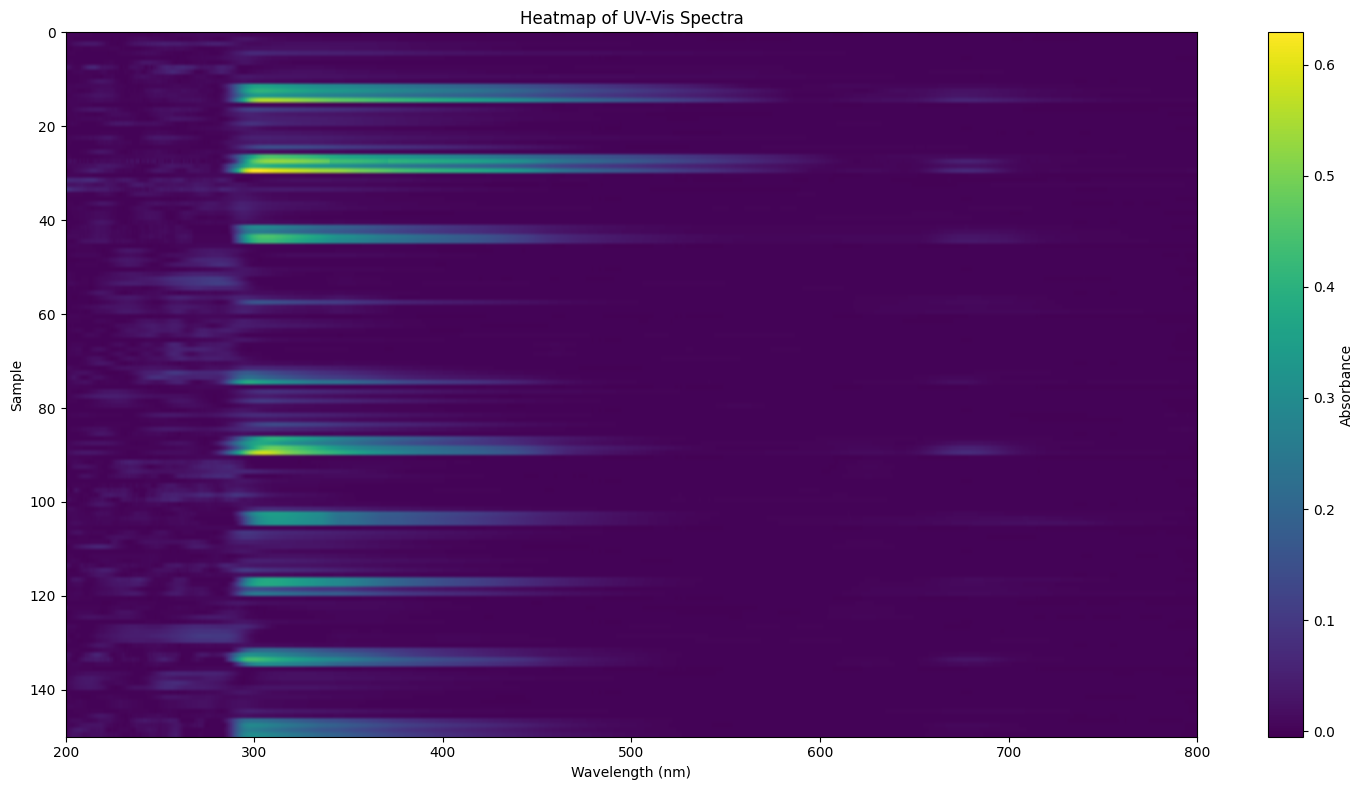

In [ ]:
plt.figure(figsize=(15,8))

plt.imshow(
    X_spec,
    aspect="auto",
    cmap="viridis",
    extent=[
        wavelength[0],
        wavelength[-1],
        len(X_spec),
        0
    ]
)

plt.colorbar(label="Absorbance")

plt.xlabel("Wavelength (nm)")

plt.ylabel("Sample")

plt.title("Heatmap of UV-Vis Spectra")

plt.tight_layout()

plt.show()

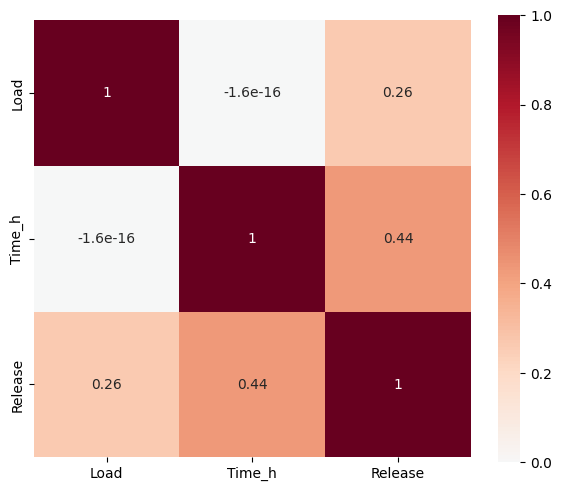

In [ ]:
corr_cols = [
    "Load",
    "Time_h",
    "Release"
]

# Menyaring kolom yang hanya ada di dalam DataFrame
existing_corr_cols = [col for col in corr_cols if col in df.columns]

corr = df[existing_corr_cols].corr()

plt.figure(figsize=(6,5))

sns.heatmap(
    corr,
    annot=True,
    cmap="RdBu_r",
    center=0,
    square=True
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# SAVE DATASET FOR NOTEBOOK 2
# ==========================================================

df.to_excel(
    "Dataset_EDA.xlsx",
    index=False
)

print("Dataset berhasil disimpan.")

Dataset berhasil disimpan.


In [ ]:
df.to_pickle(
    "Dataset_EDA.pkl"
)

print("Dataset pickle berhasil disimpan.")

Dataset pickle berhasil disimpan.


In [ ]:
import joblib
joblib.dump(
    df,
    "dataset_clean.pkl"
)

['dataset_clean.pkl']

In [ ]:
joblib.dump(
    spectral_cols,
    "spectral_cols.pkl"
)

joblib.dump(
    metadata_cols,
    "metadata_cols.pkl"
)

joblib.dump(
    target_cols,
    "target_cols.pkl"
)

['target_cols.pkl']